In [1]:
import sys
import os

#####################
# Import of utils.py functions
#####################
# Required to get utils.py and access its functions
notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist, interactive_MCQ

#############################
# Loading fsl within Neurodesk
# You can find the list of available other modules by clicking on the "Softwares" tab on the left
#############################
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.list()

####################
# Setup FSL path
####################
loadFSL()

####################
# DIPY_HOME should be set prior to import of dipy to make sure all downloads point to the right folder
####################
os.environ["DIPY_HOME"] = "/home/jovyan/data/Desktop/myfiles/NSSP_MiniProjects/derivatives"

###################
# Load other relevant libraries for the lab
##################
import fsl.wrappers, statsmodels
from fsl.wrappers import fslmaths
import dipy
import os.path as op
import nibabel as nib

##### Load other relevant packages
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tools.sm_exceptions import ConvergenceWarning
import matplotlib.pyplot as plt

# initilize GUI
%gui wx

################
# Start FSLeyes (very neat tool to visualize MRI data of all sorts) within Python
################
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()


(ipykernel_launcher.py:1061): dbind-WARNING **: 17:03:14.989: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/911243400/at-spi/bus_100: No such file or directory

(ipykernel_launcher.py:1061): Gtk-CRITICAL **: 17:03:15.219: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:1061): Gtk-CRITICAL **: 17:03:15.238: gtk_window_resize: assertion 'width > 0' failed


In [3]:
# load data 
fMRI_data_root = op.join(notebook_dir, 'fMRI', 'tfMRI_LANGUAGE_LR')
fMRI_data_filepath = op.join(fMRI_data_root, 'tfMRI_LANGUAGE_LR.nii.gz')
fMRI_task_data = op.join(fMRI_data_root, 'tfMRI_LANGUAGE_LR_task_onsets.csv')
derivatives_folder = op.join(notebook_dir, 'derivatives')

### CHANGE ####
final_fMRI = nib.load(op.join(derivatives_folder, 'tfMRI_LANGUAGE_LR_moco_smoothed-6mm.nii.gz'))

In [4]:
# The task consists of two runs that each interleave 4 blocks of a story task and 4 blocks of
# a math task. The lengths of the blocks vary (average of approximately 30 seconds),
# but the task was designed so that the math task blocks match the length of the story
# task blocks, with some additional math trials at the end of the task to complete the
# 3.8 minute run as needed. The story blocks present participants with brief auditory
# stories (5-9 sentences) adapted from Aesop’s fables, followed by a 2-alternative
# forced-choice question that asks participants about the topic of the story. The
# example provided in the original Binder paper (p. 1466) is “For example, after a story
# about an eagle that saves a man who had done him a favor, participants were asked,
# “Was that about revenge or reciprocity?” The math task also presents trials
# auditorially and requires subjects to complete addition and subtraction problems.
# The trials present subjects with a series of arithmetic operations (e.g., “fourteen plus
# twelve”), followed by “equals” and then two choices (e.g., “twenty-nine or
# twenty-six”). Participants push a button to select either the first or the second
# answer. The math task is adaptive to try to maintain a similar level of difficulty across
# participants

# load the experiment design
events = pd.read_csv(fMRI_task_data)
events

,onset,duration,trial_type
0,0.241,28.270,story
1,0.241,20.445,present_story
2,21.192,1.161,question_story
3,25.550,2.961,response_story
4,28.696,0.727,cue
5,30.095,5.667,present_math
6,30.095,12.241,math
7,35.946,3.391,question_math
8,39.371,2.965,response_math
9,42.570,5.453,present_math


Repetition Time (TR): 0.7200000286102295 seconds


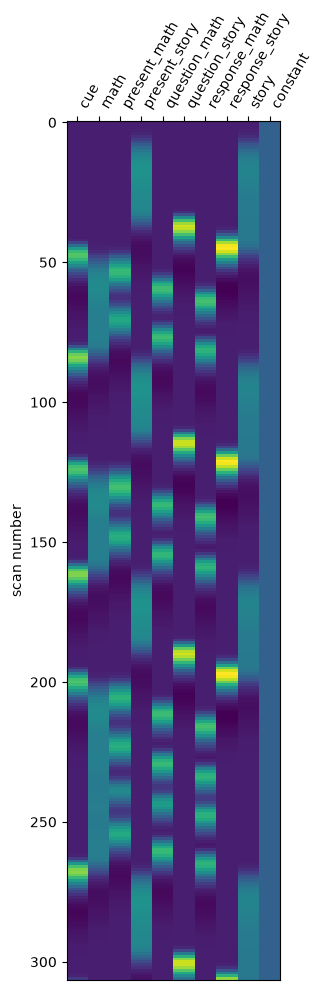

In [6]:
from nilearn.glm.first_level import make_first_level_design_matrix, FirstLevelModel

# extract TR from NIFTI header of fMRI file
fmri_orig = nib.load(fMRI_data_filepath)
tr = fmri_orig.header.get_zooms()[3]
print(f"Repetition Time (TR): {tr} seconds")

# Specify what sort of GLM we want (nature of the noise, repetition time of the data and other parameters)
fmri_glm = FirstLevelModel(t_r=float(tr),
                           noise_model='ar1',
                           standardize=False,
                           hrf_model='spm',
                           drift_model=None,
                           high_pass=.1)
# Fit the model to our design and data
fmri_glm = fmri_glm.fit(final_fMRI, events)

from nilearn.plotting import plot_design_matrix

#### CREATE THE DESIGN MATRIX AND DISPLAY IT
design_mat = fmri_glm.design_matrices_[0]
plot_design_matrix(design_mat)
plt.show()

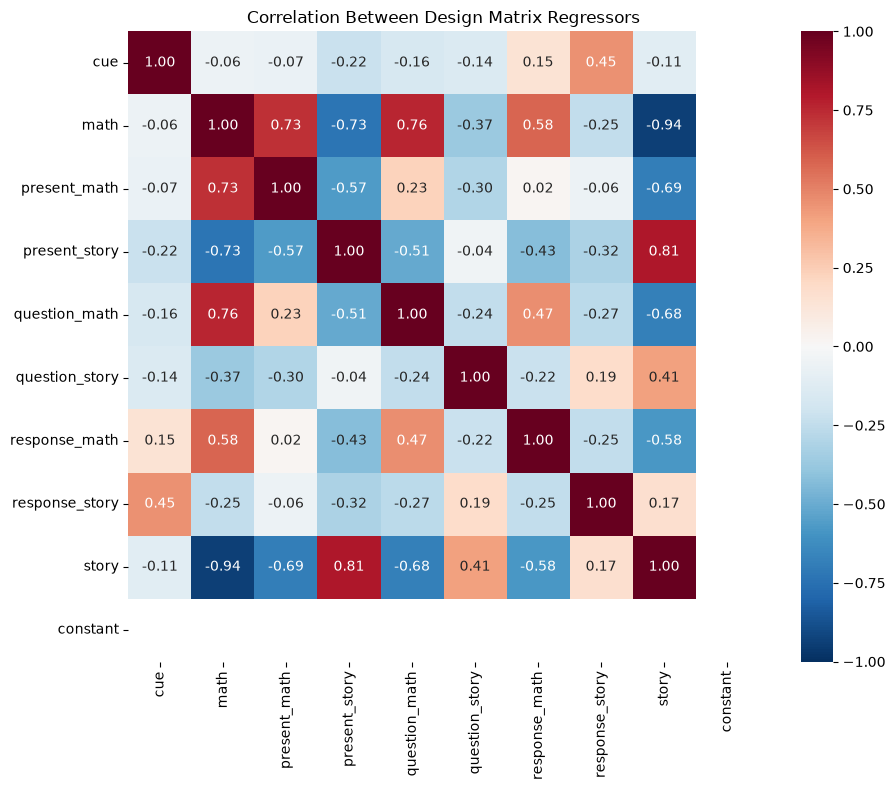

In [8]:
##### COMPUTE AND PLOT THE CORRELATION MATRIX BETWEEN REGRESSORS OF THE DESIGN MATRIX 
import seaborn as sns

# Compute the Pearson correlation between columns
corr_matrix = design_mat.corr()

# Plot the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)
plt.title("Correlation Between Design Matrix Regressors")
plt.tight_layout()
plt.show()

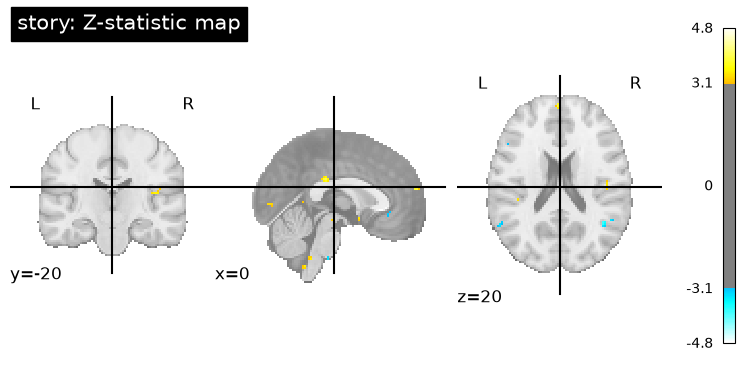

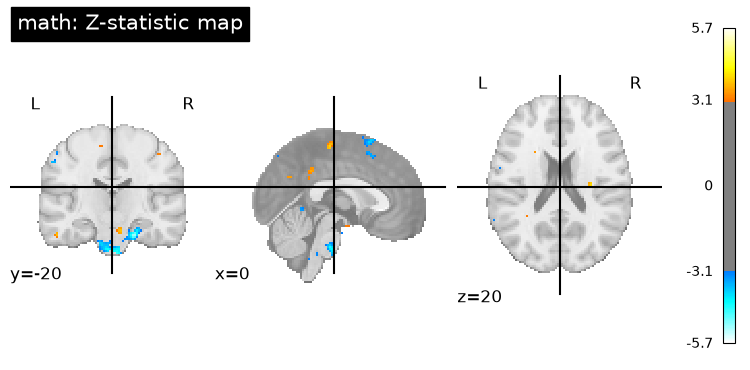

In [10]:
###### CREATE STATISTICAL MAPS OF EACH OF THE TASK-RELATED REGRESSORS
task_conditions = ["story", "math"]

from nilearn import plotting
for condition in task_conditions:
    # Test the effect of this condition relative to baseline
    z_map = fmri_glm.compute_contrast(condition, output_type="z_score")

    # Save the statistical map
    z_map.to_filename(f"{condition}_zmap.nii.gz")

    # Plot/display the map
    plotting.plot_stat_map(
        z_map,
        title=f"{condition}: Z-statistic map",
        threshold=3.1,
        display_mode="ortho",
        cut_coords=(0, -20, 20),
        colorbar=True)
    plt.show()

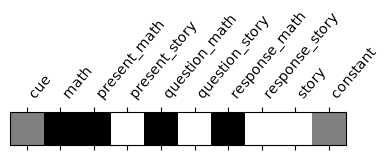

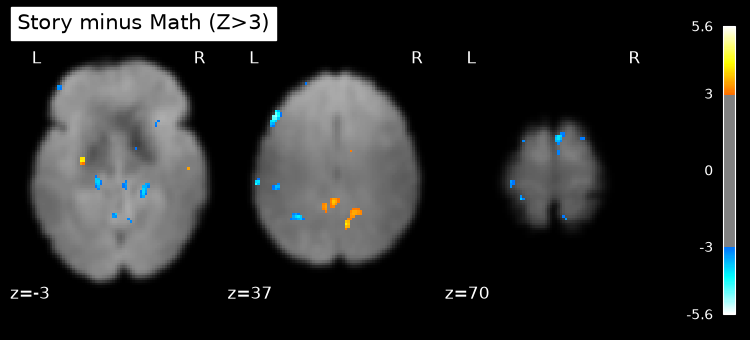

In [13]:
########### ACTIVATION MAP GENERATION 
# Create the dictionary of the conditions
conditions = {
   'story': np.array([0,0,0,1,0,1,0,1,1,0]),
    'math':np.array([0,1,1,0,1,0,1,0,0,0]),
}

story_minus_math = conditions['story'] - conditions['math']

from nilearn.plotting import plot_contrast_matrix
plot_contrast_matrix(story_minus_math, design_matrix=fmri_glm.design_matrices_[0])

z_map = fmri_glm.compute_contrast(story_minus_math, output_type='z_score')

nib.save(z_map, 'z_map_uncorrected.nii.gz')

from nilearn.plotting import plot_stat_map
from nilearn.image import mean_img
mean_img_ = mean_img(final_fMRI),
plot_stat_map(z_map, bg_img=mean_img_[0], threshold=3.0,
              display_mode='z', cut_coords=[-3,37,70], black_bg=True,
              title='Story minus Math (Z>3)')
plt.show()